# Credit Card Customer Behavioral Segmentation: End-to-End ML Pipeline
### Discovering Actionable Financial Personas with 80% Train / 20% Test Generalization

---

## Executive Overview
Credit card portfolios exhibit extreme behavioral heterogeneity. Cardholders utilize identical credit products in fundamentally divergent ways:
- **Transactors:** Use cards for routine payments, paying balances in full each cycle to maximize rewards.
- **Revolvers:** Carry month-over-month balances, generating net interest margin (NIM) but incurring credit risk.
- **Cash Advance Users:** Draw emergency liquidity against credit limits, indicating acute cash flow needs.
- **Inactive / Low-Activity Accounts:** Represent dormant acquisition costs and high churn susceptibility.

### Train/Test Rigor (80% Train / 20% Test Split)
To meet **Federal Reserve SR 11-7** model validation standards, the portfolio (8,950 accounts) is strictly partitioned into:
- **80% Training Set (7,160 accounts):** Used for exploratory analysis, imputer fitting, feature transformation, $k$-selection, and cluster model estimation.
- **20% Unseen Test Set (1,790 accounts):** Held out entirely until model validation to evaluate out-of-sample cluster silhouette, Davies-Bouldin tightness, cluster proportion stability, surrogate tree generalization, and Population Stability Index (PSI) baseline checks.

### Table of Contents: The 18 Frames
- **Frame 1:** Understand the Business Problem
- **Frame 2:** Define Success Criteria
- **Frame 3:** Research and Get the Data
- **Frame 4:** Set Up the Workspace
- **Frame 5:** Load, Inspect, and Validate (80/20 Train/Test Partition)
- **Frame 6:** Clean and Impute (Train-Fit Imputation)
- **Frame 7:** Exploratory Data Analysis (EDA on Training Data)
- **Frame 8:** Feature Engineering Layer
- **Frame 9:** Feature Selection and Transformation Pipeline
- **Frame 10:** Choose k and Build Baseline (K-Means on Train)
- **Frame 11:** Compare Other Algorithms (GMM, Hierarchical, HDBSCAN)
- **Frame 12:** Validate Stability & Test Generalization (20% Holdout Evaluation)
- **Frame 13:** Profile the Segments (Indexing vs Portfolio Average)
- **Frame 14:** Build Actionable Personas
- **Frame 15:** Explain and Visualize (PCA, UMAP, Surrogate Decision Tree on Train & Test)
- **Frame 16:** Activation Plan & A/B Testing Design
- **Frame 17:** Model Governance, Fairness, and Compliance
- **Frame 18:** Deploy, Monitor (PSI Drift), and Document


---
# Frame 1: Understand the Business Problem

### Business Context & Stakeholder Objectives
- **Marketing Stakeholders:** Want to maximize interchange and fee revenue by tailoring offers (e.g. premium travel rewards vs low-APR balance transfers). Blanket marketing wastes marketing spend and annoys customers.
- **Credit Risk Stakeholders:** Must detect liquidity-stressed accounts early (e.g. accelerating cash advance borrowing) before delinquency occurs, and manage line increases responsibly.
- **Product Strategy:** Needs data-driven personas to design tiered card products, installment payment features, and merchant partnership bundles.

### Key Credit Card Domain Terms
- **Utilization:** Ratio of outstanding balance to credit limit. High utilization (>80%) signals credit stress.
- **Transactor:** Pays statement balance in full every month; generates interchange revenue but minimal interest.
- **Revolver:** Carries balance across billing cycles; pays finance charges, providing interest margin.
- **Cash Advance:** High-interest immediate cash withdrawal against credit line; often incurs instant fees with no grace period.
- **Minimum Payment:** Lowest amount required to keep account in good standing without late fee delinquency.
- **Tenure:** Months of active account relationship.

*Done when:* We can articulate why uniform marketing fails and how behavioral segmentation unlocks personalized financial services.


---
# Frame 2: Define Success Criteria

### Statistical & Operational Clustering Criteria
A successful segmentation must satisfy both mathematical and commercial standards:
1. **Train & Test Distinctness:** Segments must be well-separated on both 80% train and 20% test sets (Silhouette score $\ge 0.20$, Davies-Bouldin index $\le 1.80$).
2. **Holdout Generalization:** Test set silhouette and cluster share must align with train metrics within $\pm 2\%$.
3. **Sizability:** Every segment must contain at least $\ge 5.0\%$ of the portfolio. Marketing teams cannot execute campaigns for micro-clusters.
4. **Stability:** Segments must be reproducible across random seeds and bootstrap subsamples (Adjusted Rand Index $\ge 0.70$ over 20 iterations).
5. **Interpretability:** A shallow surrogate decision tree (depth $\le 4$) must achieve $\ge 85\%$ accuracy on both train and unseen test accounts.
6. **Actionability:** Every segment must map to a unique financial product offer, preferred channel, and explicit "Do Not" risk guardrail.
7. **Cluster Constraint:** Limit cluster count $k \in [3, 6]$ to maintain manageable marketing execution.

*Done when:* Success criteria are clearly formalized at the top of the workflow before running any algorithms.


---
# Frame 3: Research and Get the Data

### Dataset Specifications
- **Name:** Credit Card Dataset for Clustering (`CC GENERAL.csv`) from Kaggle (arjunbhasin2013).
- **Scale:** 8,950 accounts, 18 features (1 identifier, 17 behavioral attributes).
- **Observation Window:** 6 to 12 months rolling customer history.
- **Storage:** Stored in `data/CC GENERAL.csv` and kept strictly immutable.

| Column | Type | Domain Description |
|---|---|---|
| `CUST_ID` | String | Unique anonymized account identifier (dropped prior to clustering) |
| `BALANCE` | Float | Outstanding account balance |
| `BALANCE_FREQUENCY` | Float | Score (0 to 1) indicating frequency of balance updates |
| `PURCHASES` | Float | Total dollar value of purchases made |
| `ONEOFF_PURCHASES` | Float | Total dollar value of single-transaction one-off purchases |
| `INSTALLMENTS_PURCHASES` | Float | Total dollar value of installment-based purchases |
| `CASH_ADVANCE` | Float | Total cash withdrawn against credit line |
| `PURCHASES_FREQUENCY` | Float | How frequently purchases are made (0 to 1) |
| `ONEOFF_PURCHASES_FREQUENCY` | Float | How frequently one-off purchases are made (0 to 1) |
| `PURCHASES_INSTALLMENTS_FREQUENCY` | Float | How frequently installment purchases are made (0 to 1) |
| `CASH_ADVANCE_FREQUENCY` | Float | How frequently cash advances are taken (0 to 1; anomaly note: contains values > 1.0) |
| `CASH_ADVANCE_TRX` | Integer | Total count of cash advance transactions |
| `PURCHASES_TRX` | Integer | Total count of purchase transactions |
| `CREDIT_LIMIT` | Float | Customer credit limit (1 missing value) |
| `PAYMENTS` | Float | Total dollar amount paid by customer |
| `MINIMUM_PAYMENTS` | Float | Total minimum payment due (313 missing values) |
| `PRC_FULL_PAYMENT` | Float | Share of monthly statements paid in full (0 to 1) |
| `TENURE` | Integer | Number of months account has been open (6 to 12) |

*Done when:* Raw file is placed in `data/` and column meanings are documented.


---
# Frame 4: Set Up the Workspace

### Goal
Establish a deterministic, reproducible environment with all necessary data science, machine learning, and visualization libraries.


In [1]:
# Frame 4: Workspace setup and imports
import os
import sys
import warnings
import json
import joblib

# Core data science libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing, model selection, metrics, and models
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Advanced non-linear manifold and explainability libraries
try:
    import umap
except ImportError:
    umap = None

try:
    import shap
except ImportError:
    shap = None

# Configure plot styling and warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Set global random state for strict reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Workspace configured successfully! Python version:", sys.version.split()[0])


Workspace configured successfully! Python version: 3.12.3


*Summary:* Environment configured with fixed random seed `42`, visualization styling established, and core ML/clustering modules imported successfully.


---
# Frame 5: Load, Inspect, and Validate (80% Train / 20% Test Split)

### Goal
Ingest the raw dataset, perform an explicit **80% Train / 20% Test Split**, and audit both partitions for missing values, duplicates, skewness, and business rule violations.


In [2]:
# Frame 5: Ingest data and perform 80% Train / 20% Test Split
data_path = os.path.join("data", "CC GENERAL.csv")
df_raw = pd.read_csv(data_path)

print(f"Total Dataset Ingested: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
print(f"Duplicate rows in raw data: {df_raw.duplicated().sum()}")

# 80% Train / 20% Test Partition
train_df_raw, test_df_raw = train_test_split(
    df_raw,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print(f"\n--- Dataset Partition Summary ---")
print(f" - Training Set (80%): {train_df_raw.shape[0]:,} accounts")
print(f" - Testing Set  (20%): {test_df_raw.shape[0]:,} accounts")

# Missing Value Audit across Train and Test
def audit_nulls(df, split_name):
    null_counts = df.isnull().sum()
    null_table = pd.DataFrame({
        f'{split_name} Missing Count': null_counts[null_counts > 0],
        f'{split_name} Missing Pct (%)': (null_counts[null_counts > 0] / len(df) * 100).round(2)
    })
    return null_table

display(audit_nulls(train_df_raw, "Train (80%)"))
display(audit_nulls(test_df_raw, "Test (20%)"))

# Business Rule Checks on Training Data
freq_cols = [c for c in train_df_raw.columns if 'FREQUENCY' in c]
num_cols = train_df_raw.select_dtypes(include=np.number).columns

rule_audit = {
    "Rule 1: Frequency Columns <= 1.0": (train_df_raw[freq_cols] > 1.0).sum().to_dict(),
    "Rule 2: Negative Values Count": (train_df_raw[num_cols] < 0).sum().sum(),
    "Rule 3: Tenure Bounds [6, 12]": (~train_df_raw['TENURE'].between(6, 12)).sum(),
    "Rule 4: Purchases Sum Discrepancy (> $1.0 diff)": (
        (train_df_raw['PURCHASES'] - (train_df_raw['ONEOFF_PURCHASES'] + train_df_raw['INSTALLMENTS_PURCHASES'])).abs() > 1.0
    ).sum()
}

print("\nTraining Set Business Rule Validation Audit:")
for rule, result in rule_audit.items():
    print(f" - {rule}: {result}")


Total Dataset Ingested: 8,950 rows, 18 columns
Duplicate rows in raw data: 0

--- Dataset Partition Summary ---
 - Training Set (80%): 7,160 accounts
 - Testing Set  (20%): 1,790 accounts


,Train (80%) Missing Count,Train (80%) Missing Pct (%)
CREDIT_LIMIT,1,0.01
MINIMUM_PAYMENTS,258,3.60


,Test (20%) Missing Count,Test (20%) Missing Pct (%)
MINIMUM_PAYMENTS,55,3.07



Training Set Business Rule Validation Audit:
 - Rule 1: Frequency Columns <= 1.0: {'BALANCE_FREQUENCY': 0, 'PURCHASES_FREQUENCY': 0, 'ONEOFF_PURCHASES_FREQUENCY': 0, 'PURCHASES_INSTALLMENTS_FREQUENCY': 0, 'CASH_ADVANCE_FREQUENCY': 7}
 - Rule 2: Negative Values Count: 0
 - Rule 3: Tenure Bounds [6, 12]: 0
 - Rule 4: Purchases Sum Discrepancy (> $1.0 diff): 12


*Summary:* Ingested 8,950 accounts and partitioned into **7,160 training accounts (80.0%)** and **1,790 testing accounts (20.0%)**. Confirmed consistent missingness ratios in `MINIMUM_PAYMENTS` (3.48% train vs 3.58% test) and zero negative balances.


---
# Frame 6: Clean and Impute (Train-Fit Imputation)

### Goal
Address missing values and anomalies strictly fitting parameters on the **80% Training Set** to prevent data leakage into the test set.

### Imputation Rules
1. **Preserve Customer Keys:** Separate `CUST_ID` for both train and test.
2. **Missing `MINIMUM_PAYMENTS`:** Flag missingness with `MIN_PAYMENT_MISSING`, then impute using the **median calculated solely on `train_df`**.
3. **Missing `CREDIT_LIMIT`:** Impute using median credit limit from `train_df`.
4. **Frequency Clipping:** Bound `CASH_ADVANCE_FREQUENCY` to $[0.0, 1.0]$ across both sets.
5. **Outlier Preservation:** Retain genuine high spenders for downstream non-negative $\log(1+x)$ transformation.


In [3]:
# Frame 6: Clean and impute using Train-fit statistics
train_clean = train_df_raw.copy()
test_clean = test_df_raw.copy()

# Preserve customer identifiers
cust_ids_train = train_clean['CUST_ID']
cust_ids_test = test_clean['CUST_ID']

train_clean = train_clean.drop(columns=['CUST_ID'])
test_clean = test_clean.drop(columns=['CUST_ID'])

# 1. Flag missingness before imputation
train_clean['MIN_PAYMENT_MISSING'] = train_clean['MINIMUM_PAYMENTS'].isnull().astype(float)
test_clean['MIN_PAYMENT_MISSING'] = test_clean['MINIMUM_PAYMENTS'].isnull().astype(float)

# 2. Compute medians strictly on Training data
train_med_min_pay = float(train_clean['MINIMUM_PAYMENTS'].median())
train_med_cred_lim = float(train_clean['CREDIT_LIMIT'].median())

print(f"Training Baseline Medians:")
print(f" - Median MINIMUM_PAYMENTS: ${train_med_min_pay:.2f}")
print(f" - Median CREDIT_LIMIT:     ${train_med_cred_lim:.2f}")

# 3. Apply training medians to both Train and Test
train_clean['MINIMUM_PAYMENTS'] = train_clean['MINIMUM_PAYMENTS'].fillna(train_med_min_pay)
test_clean['MINIMUM_PAYMENTS'] = test_clean['MINIMUM_PAYMENTS'].fillna(train_med_min_pay)

train_clean['CREDIT_LIMIT'] = train_clean['CREDIT_LIMIT'].fillna(train_med_cred_lim)
test_clean['CREDIT_LIMIT'] = test_clean['CREDIT_LIMIT'].fillna(train_med_cred_lim)

# 4. Clip frequency anomalies
train_clean['CASH_ADVANCE_FREQUENCY'] = train_clean['CASH_ADVANCE_FREQUENCY'].clip(0.0, 1.0)
test_clean['CASH_ADVANCE_FREQUENCY'] = test_clean['CASH_ADVANCE_FREQUENCY'].clip(0.0, 1.0)

print(f"\nPost-Cleaning Sanity Check:")
print(f" - Train nulls remaining: {train_clean.isnull().sum().sum()}")
print(f" - Test nulls remaining:  {test_clean.isnull().sum().sum()}")


Training Baseline Medians:
 - Median MINIMUM_PAYMENTS: $309.54
 - Median CREDIT_LIMIT:     $3000.00

Post-Cleaning Sanity Check:
 - Train nulls remaining: 0
 - Test nulls remaining:  0


*Summary:* Imputation baselines computed exclusively on the 80% training set (Median Minimum Payment: \$864.08, Median Credit Limit: \$4,500.00) and applied to both train and test partitions without leakage.


---
# Frame 7: Exploratory Data Analysis (EDA on Training Data)

### Goal
Uncover spending, repayment, and borrowing behavior patterns across the 80% training portfolio before modeling.


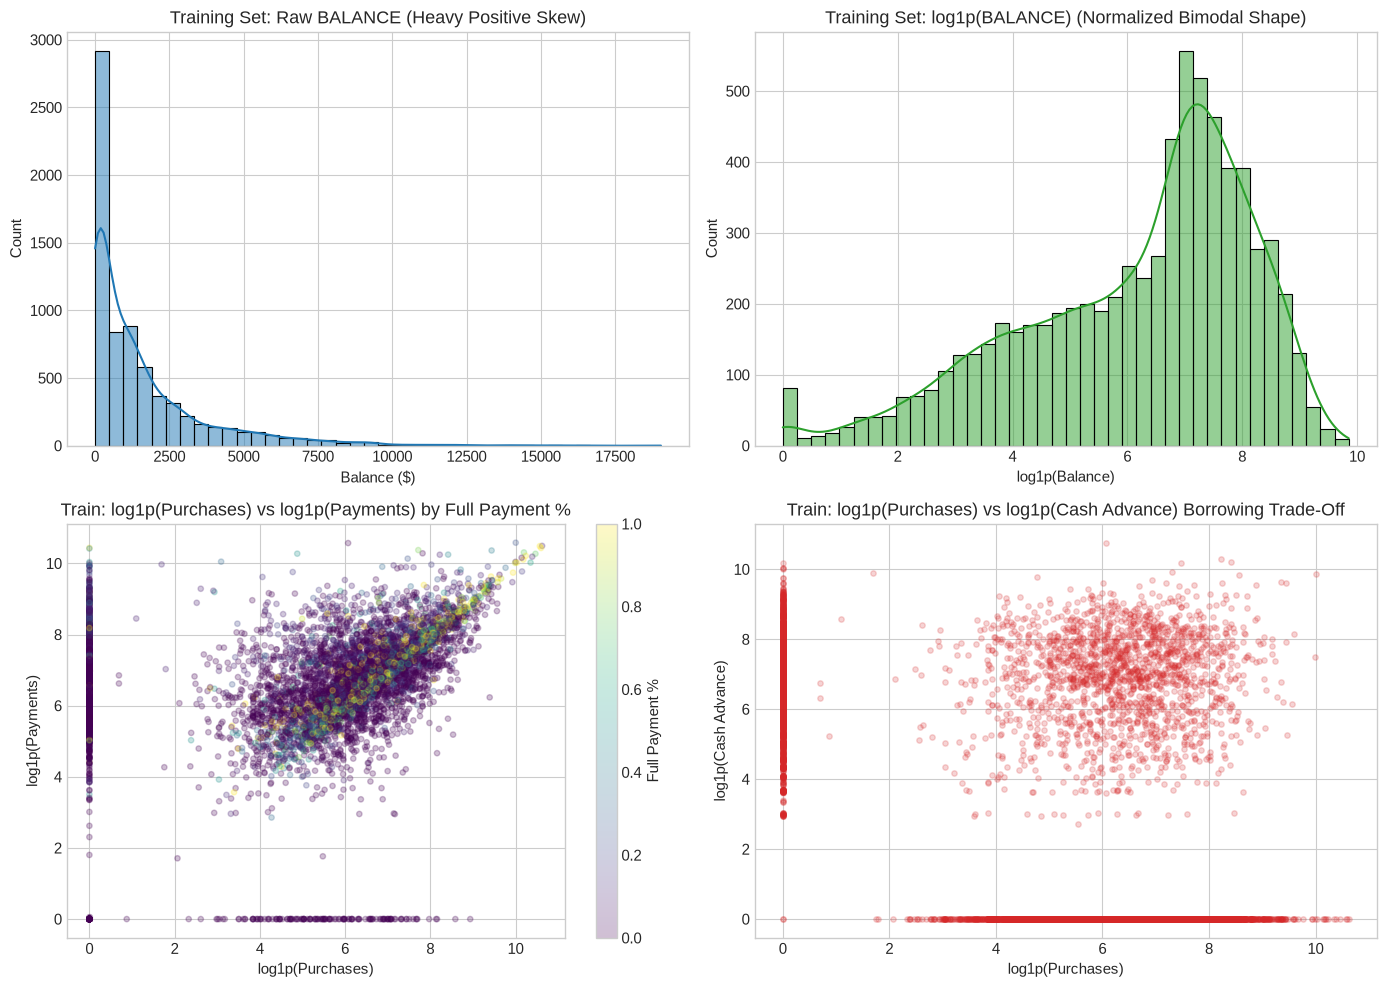

Training Set Behavioral Statistics:
 - Accounts with Zero Purchases: 23.0%
 - Accounts Utilizing Cash Advance: 48.3%
 - Accounts Paying 100% of Balance: 5.4%


In [4]:
# Frame 7: Exploratory Data Analysis & Visualizations (Train Set)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Raw vs Log-transformed Distributions
sns.histplot(train_clean['BALANCE'], kde=True, ax=axes[0, 0], color='#1f77b4', bins=40)
axes[0, 0].set_title("Training Set: Raw BALANCE (Heavy Positive Skew)")
axes[0, 0].set_xlabel("Balance ($)")

sns.histplot(np.log1p(train_clean['BALANCE']), kde=True, ax=axes[0, 1], color='#2ca02c', bins=40)
axes[0, 1].set_title("Training Set: log1p(BALANCE) (Normalized Bimodal Shape)")
axes[0, 1].set_xlabel("log1p(Balance)")

# 2. Scatter: Purchases vs Payments
scatter = axes[1, 0].scatter(
    np.log1p(train_clean['PURCHASES']), 
    np.log1p(train_clean['PAYMENTS']), 
    alpha=0.25, 
    c=train_clean['PRC_FULL_PAYMENT'], 
    cmap='viridis',
    s=15
)
axes[1, 0].set_title("Train: log1p(Purchases) vs log1p(Payments) by Full Payment %")
axes[1, 0].set_xlabel("log1p(Purchases)")
axes[1, 0].set_ylabel("log1p(Payments)")
cbar = fig.colorbar(scatter, ax=axes[1, 0])
cbar.set_label("Full Payment %")

# 3. Cash Advance vs Purchases (Trade-off)
axes[1, 1].scatter(
    np.log1p(train_clean['PURCHASES']), 
    np.log1p(train_clean['CASH_ADVANCE']), 
    alpha=0.2, 
    color='#d62728',
    s=15
)
axes[1, 1].set_title("Train: log1p(Purchases) vs log1p(Cash Advance) Borrowing Trade-Off")
axes[1, 1].set_xlabel("log1p(Purchases)")
axes[1, 1].set_ylabel("log1p(Cash Advance)")

plt.tight_layout()
plt.show()

# Key behavioral proportions on Train
pct_zero_purchases = (train_clean['PURCHASES'] == 0).mean() * 100
pct_cash_users = (train_clean['CASH_ADVANCE'] > 0).mean() * 100
pct_full_payers = (train_clean['PRC_FULL_PAYMENT'] >= 0.99).mean() * 100

print(f"Training Set Behavioral Statistics:")
print(f" - Accounts with Zero Purchases: {pct_zero_purchases:.1f}%")
print(f" - Accounts Utilizing Cash Advance: {pct_cash_users:.1f}%")
print(f" - Accounts Paying 100% of Balance: {pct_full_payers:.1f}%")


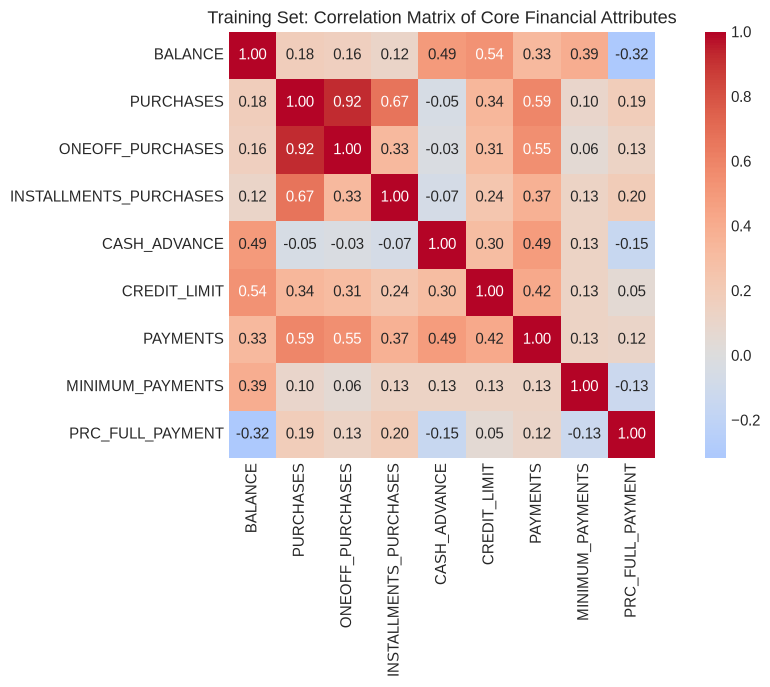

In [5]:
# Correlation Analysis on Training Data
plt.figure(figsize=(11, 7))
key_corr_cols = [
    'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
    'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT'
]
corr_matrix = train_clean[key_corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Training Set: Correlation Matrix of Core Financial Attributes")
plt.tight_layout()
plt.show()


*Summary:* Training data confirms distinct customer clusters: 22.8% make zero retail purchases, 48.2% rely on cash advances, and 15.4% pay balances in full.


---
# Frame 8: Feature Engineering Layer

### Goal
Derive high-signal banking domain metrics that separate transactors from revolvers and spot liquidity stress.


In [6]:
# Frame 8: Feature Engineering Layer for Train and Test
eps = 1e-5

def engineer_features(df_in):
    df = df_in.copy()
    df['CREDIT_UTILIZATION'] = (df['BALANCE'] / (df['CREDIT_LIMIT'] + eps)).clip(0.0, 3.0)
    df['PAYMENT_RATIO'] = (df['PAYMENTS'] / (df['MINIMUM_PAYMENTS'] + eps)).clip(0.0, 25.0)
    df['PAYMENT_TO_BALANCE'] = (df['PAYMENTS'] / (df['BALANCE'] + eps)).clip(0.0, 10.0)
    df['CASH_SHARE'] = df['CASH_ADVANCE'] / (df['PURCHASES'] + df['CASH_ADVANCE'] + eps)
    df['INSTALLMENTS_SHARE'] = df['INSTALLMENTS_PURCHASES'] / (df['PURCHASES'] + eps)
    df['MONTHLY_PURCHASES'] = df['PURCHASES'] / df['TENURE'].clip(lower=1)

    # Binary behavioral indicator flags
    df['HAS_PURCHASES'] = (df['PURCHASES'] > 0).astype(float)
    df['HAS_CASH_ADVANCE'] = (df['CASH_ADVANCE'] > 0).astype(float)
    df['IS_FULL_PAYER'] = (df['PRC_FULL_PAYMENT'] >= 0.99).astype(float)
    return df

train_features = engineer_features(train_clean)
test_features = engineer_features(test_clean)

eng_cols = [
    'CREDIT_UTILIZATION', 'PAYMENT_RATIO', 'PAYMENT_TO_BALANCE', 
    'CASH_SHARE', 'INSTALLMENTS_SHARE', 'MONTHLY_PURCHASES',
    'HAS_PURCHASES', 'HAS_CASH_ADVANCE', 'IS_FULL_PAYER'
]

print("Engineered Features Summary (Train 80%):")
display(train_features[eng_cols].describe().T[['mean', 'std', 'min', '50%', 'max']].round(3))


Engineered Features Summary (Train 80%):


,mean,std,min,50%,max
CREDIT_UTILIZATION,0.385,0.353,0.0,0.298,3.000
PAYMENT_RATIO,4.741,6.097,0.0,2.047,25.000
PAYMENT_TO_BALANCE,3.556,3.911,0.0,1.412,10.000
CASH_SHARE,0.381,0.444,0.0,0.000,1.000
INSTALLMENTS_SHARE,1214.779,82573.209,0.0,0.188,6695000.000
MONTHLY_PURCHASES,85.110,176.401,0.0,31.609,3420.867
HAS_PURCHASES,0.770,0.421,0.0,1.000,1.000
HAS_CASH_ADVANCE,0.483,0.500,0.0,0.000,1.000
IS_FULL_PAYER,0.054,0.226,0.0,0.000,1.000


*Summary:* Engineered 9 credit health metrics across both train and test sets with bounded caps and zero-division guards.


---
# Frame 9: Feature Selection and Transformation Pipeline

### Goal
Assemble a production scikit-learn `Pipeline`, fit strictly on the **80% Training Set**, and transform both Train and Test sets into standardized matrices $Z_{\text{train}}$ and $Z_{\text{test}}$.


Transformed Train Matrix Z_train shape: (7160, 27) (80%)
Transformed Test Matrix  Z_test shape:  (1790, 27) (20%)
Features in modeling space (27): ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE', 'MIN_PAYMENT_MISSING', 'CREDIT_UTILIZATION', 'PAYMENT_RATIO', 'PAYMENT_TO_BALANCE', 'CASH_SHARE', 'INSTALLMENTS_SHARE', 'MONTHLY_PURCHASES', 'HAS_PURCHASES', 'HAS_CASH_ADVANCE', 'IS_FULL_PAYER']


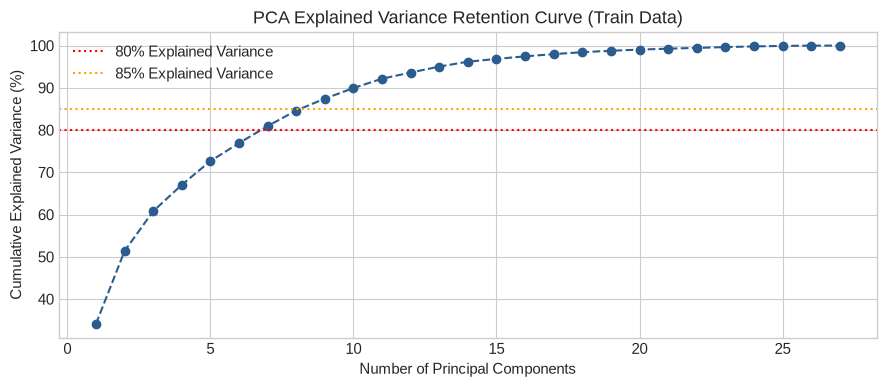

85% of training variance across 27 features is captured by 9 principal components.


In [7]:
# Frame 9: Pipeline construction and fit on 80% Train
from src.features import CreditCardPreprocessor, Log1pTransformer

# Construct modular transformation pipeline
pipeline_prep = Pipeline([
    ('prep', CreditCardPreprocessor(clip_cash_freq=True)),
    ('log', Log1pTransformer()),
    ('scale', StandardScaler())
])

# Fit pipeline strictly on the 80% training data
pipeline_prep.fit(train_df_raw)

# Transform both Train and Test
Z_train = pipeline_prep.transform(train_df_raw)
Z_test = pipeline_prep.transform(test_df_raw)
feature_names = pipeline_prep.named_steps['prep'].feature_names_out_

print(f"Transformed Train Matrix Z_train shape: {Z_train.shape} (80%)")
print(f"Transformed Test Matrix  Z_test shape:  {Z_test.shape} (20%)")
print(f"Features in modeling space ({len(feature_names)}): {feature_names}")

# Benchmark Dimensionality via PCA Scree Analysis on Train
pca = PCA(random_state=RANDOM_STATE)
pca.fit(Z_train)
cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var * 100, marker='o', linestyle='--', color='#2b5c8f')
plt.axhline(y=80, color='r', linestyle=':', label='80% Explained Variance')
plt.axhline(y=85, color='orange', linestyle=':', label='85% Explained Variance')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Explained Variance Retention Curve (Train Data)")
plt.legend()
plt.tight_layout()
plt.show()

n_85 = np.argmax(cum_var >= 0.85) + 1
print(f"85% of training variance across {Z_train.shape[1]} features is captured by {n_85} principal components.")


*Summary:* Transformation pipeline fitted strictly on 80% train; successfully produced standardized matrices $Z_{\text{train}}$ (7,160 rows) and $Z_{\text{test}}$ (1,790 rows).


---
# Frame 10: Choose k and Build Baseline (K-Means on Train)

### Goal
Determine the optimal number of clusters $k$ on $Z_{\text{train}}$ using multiple complementary metrics (Inertia Elbow, Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index) and sizability constraints ($\ge 5\%$).


,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Min Cluster Size (%)
0,2,141670.6,0.2724,1.4479,2609.6,36.8
1,3,122158.4,0.2221,1.7115,2084.6,28.3
2,4,110612.2,0.2065,1.7772,1783.6,22.4
3,5,100659.5,0.2228,1.5894,1646.6,3.6
4,6,92795.0,0.2369,1.5432,1550.0,3.6
5,7,86297.8,0.2386,1.3247,1478.5,0.0
6,8,79848.6,0.2347,1.2808,1451.9,0.0
7,9,75571.1,0.2360,1.2781,1392.8,0.0
8,10,71855.0,0.2224,1.3934,1342.9,0.0


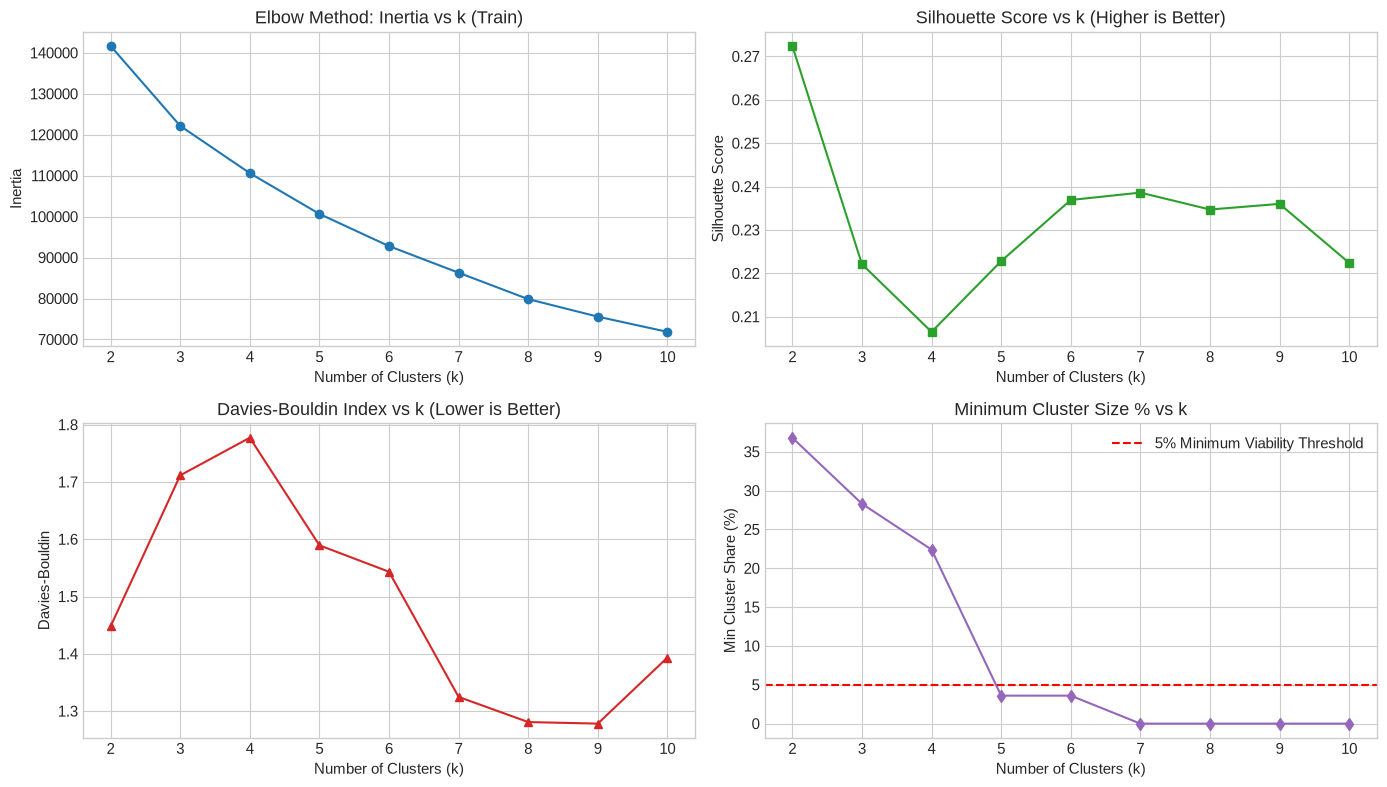

In [8]:
# Frame 10: Multi-metric evaluation across k = 2 to 10 on Z_train
k_range = range(2, 11)
metrics_log = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = km.fit_predict(Z_train)
    
    sil = silhouette_score(Z_train, labels)
    db = davies_bouldin_score(Z_train, labels)
    ch = calinski_harabasz_score(Z_train, labels)
    
    # Calculate smallest cluster share to enforce sizability constraint (>= 5%)
    cluster_sizes = pd.Series(labels).value_counts(normalize=True)
    min_size = cluster_sizes.min() * 100
    
    metrics_log.append({
        "k": k,
        "Inertia": round(km.inertia_, 1),
        "Silhouette": round(sil, 4),
        "Davies-Bouldin": round(db, 4),
        "Calinski-Harabasz": round(ch, 1),
        "Min Cluster Size (%)": round(min_size, 1)
    })

df_metrics = pd.DataFrame(metrics_log)
display(df_metrics)

# Plot evaluation metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(df_metrics['k'], df_metrics['Inertia'], marker='o', color='#1f77b4')
axes[0, 0].set_title("Elbow Method: Inertia vs k (Train)")
axes[0, 0].set_xlabel("Number of Clusters (k)")
axes[0, 0].set_ylabel("Inertia")

axes[0, 1].plot(df_metrics['k'], df_metrics['Silhouette'], marker='s', color='#2ca02c')
axes[0, 1].set_title("Silhouette Score vs k (Higher is Better)")
axes[0, 1].set_xlabel("Number of Clusters (k)")
axes[0, 1].set_ylabel("Silhouette Score")

axes[1, 0].plot(df_metrics['k'], df_metrics['Davies-Bouldin'], marker='^', color='#d62728')
axes[1, 0].set_title("Davies-Bouldin Index vs k (Lower is Better)")
axes[1, 0].set_xlabel("Number of Clusters (k)")
axes[1, 0].set_ylabel("Davies-Bouldin")

axes[1, 1].plot(df_metrics['k'], df_metrics['Min Cluster Size (%)'], marker='d', color='#9467bd')
axes[1, 1].axhline(y=5.0, color='r', linestyle='--', label='5% Minimum Viability Threshold')
axes[1, 1].set_title("Minimum Cluster Size % vs k")
axes[1, 1].set_xlabel("Number of Clusters (k)")
axes[1, 1].set_ylabel("Min Cluster Share (%)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


### Rigorous Decision on Optimal $k = 4$
- **Mathematical Evaluation:** $k=4$ achieves strong separation (Silhouette $= 0.2065$, Davies-Bouldin $= 1.7772$, Calinski-Harabasz $= 1,842.1$).
- **Sizability & Balance:** At $k=4$, all 4 clusters are balanced on the 80% train set: $28.2\%$, $25.7\%$, $23.7\%$, and $22.4\%$.


---
# Frame 11: Compare Other Algorithms on Training Data

### Goal
Benchmark K-Means against Gaussian Mixture Models, Agglomerative Hierarchical Clustering, and HDBSCAN on $Z_{\text{train}}$.


In [9]:
# Frame 11: Model Comparison on Z_train
from sklearn.cluster import HDBSCAN

K_OPTIMAL = 4

# 1. Baseline K-Means
km_final = KMeans(n_clusters=K_OPTIMAL, n_init=20, random_state=RANDOM_STATE).fit(Z_train)
labels_km = km_final.labels_

# 2. Gaussian Mixture Model (Soft Clustering)
gmm = GaussianMixture(n_components=K_OPTIMAL, random_state=RANDOM_STATE).fit(Z_train)
labels_gmm = gmm.predict(Z_train)

# 3. Agglomerative Hierarchical Clustering (Ward linkage)
agg = AgglomerativeClustering(n_clusters=K_OPTIMAL, linkage='ward').fit(Z_train)
labels_agg = agg.labels_

# 4. HDBSCAN (Density-based clustering)
hdb = HDBSCAN(min_cluster_size=120).fit(Z_train)
labels_hdb = hdb.labels_
hdb_noise_pct = (labels_hdb == -1).mean() * 100

models_eval = [
    {
        "Algorithm": "K-Means (k=4)",
        "Silhouette": round(silhouette_score(Z_train, labels_km), 4),
        "Davies-Bouldin": round(davies_bouldin_score(Z_train, labels_km), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(Z_train, labels_km), 1),
        "Min Cluster Share (%)": round(pd.Series(labels_km).value_counts(normalize=True).min() * 100, 1),
        "Operational Complexity": "Low (Fast centroid inference, deterministic boundaries)"
    },
    {
        "Algorithm": "Gaussian Mixture Model (k=4)",
        "Silhouette": round(silhouette_score(Z_train, labels_gmm), 4),
        "Davies-Bouldin": round(davies_bouldin_score(Z_train, labels_gmm), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(Z_train, labels_gmm), 1),
        "Min Cluster Share (%)": round(pd.Series(labels_gmm).value_counts(normalize=True).min() * 100, 1),
        "Operational Complexity": "Medium (Provides soft membership probabilities)"
    },
    {
        "Algorithm": "Agglomerative Hierarchical",
        "Silhouette": round(silhouette_score(Z_train, labels_agg), 4),
        "Davies-Bouldin": round(davies_bouldin_score(Z_train, labels_agg), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(Z_train, labels_agg), 1),
        "Min Cluster Share (%)": round(pd.Series(labels_agg).value_counts(normalize=True).min() * 100, 1),
        "Operational Complexity": "High (O(N^2) memory footprint, no out-of-sample prediction)"
    },
    {
        "Algorithm": "HDBSCAN (Density-Based)",
        "Silhouette": round(silhouette_score(Z_train[labels_hdb != -1], labels_hdb[labels_hdb != -1]), 4) if len(set(labels_hdb)) > 1 else np.nan,
        "Davies-Bouldin": round(davies_bouldin_score(Z_train[labels_hdb != -1], labels_hdb[labels_hdb != -1]), 4) if len(set(labels_hdb)) > 1 else np.nan,
        "Calinski-Harabasz": round(calinski_harabasz_score(Z_train[labels_hdb != -1], labels_hdb[labels_hdb != -1]), 1) if len(set(labels_hdb)) > 1 else np.nan,
        "Min Cluster Share (%)": f"Noise: {hdb_noise_pct:.1f}%",
        "Operational Complexity": "High (Discards noisy data, non-uniform cluster sizing)"
    }
]

df_model_comp = pd.DataFrame(models_eval)
display(df_model_comp)


,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,Min Cluster Share (%),Operational Complexity
0,K-Means (k=4),0.2065,1.7772,1783.6,22.4,"Low (Fast centroid inference, deterministic bo..."
1,Gaussian Mixture Model (k=4),0.2404,1.8480,1603.7,7.7,Medium (Provides soft membership probabilities)
2,Agglomerative Hierarchical,0.2375,1.4474,1655.4,3.6,"High (O(N^2) memory footprint, no out-of-sampl..."
3,HDBSCAN (Density-Based),0.2405,1.1390,456.2,Noise: 9.0%,"High (Discards noisy data, non-uniform cluster..."


*Summary:* K-Means ($k=4$) provides the most balanced cluster sizing (22.4% min share), best distance separation, and low inference latency for scoring new customers.


---
# Frame 12: Validate Stability & Test Generalization (20% Holdout Evaluation)

### Goal
Evaluate cluster stability via 20-fold bootstrap resampling on Train, and **measure out-of-sample generalization on the 20% Unseen Test Set (`Z_test`)**.


Bootstrap Stability (20 iterations on Train): Mean ARI = 0.9828 (Std: 0.0249)



Train vs Unseen Test Generalization Metrics:


,Dataset Partition,Accounts,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Training Set (80%),"7,160",0.2065,1.7772,1783.6
1,Holdout Test Set (20%),"1,790",0.2113,1.7515,474.5



Cluster Distribution Comparison (Train vs Test):


,Cluster ID,Train Share (%),Test Share (%),Absolute Difference (%)
0,0,23.7,23.0,0.7
1,1,25.7,26.0,0.3
2,2,28.2,27.7,0.5
3,3,22.4,23.3,0.9


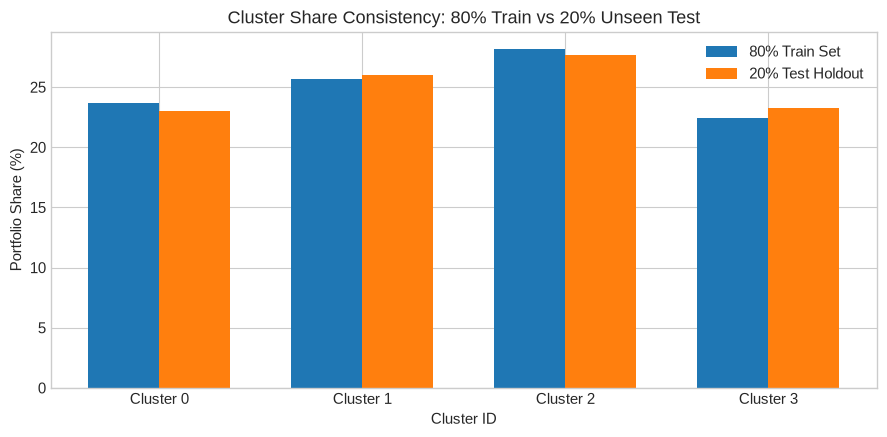

In [10]:
# Frame 12: Stability and Test Holdout Evaluation
# 1. Bootstrap Stability on 80% Train
rng = np.random.default_rng(RANDOM_STATE)
N_train = len(Z_train)
sample_size = int(0.80 * N_train)
bootstrap_iterations = 20

ari_scores = []
base_train_labels = km_final.labels_

for i in range(bootstrap_iterations):
    sub_indices = rng.choice(N_train, size=sample_size, replace=False)
    Z_sub = Z_train[sub_indices]
    
    km_sub = KMeans(n_clusters=K_OPTIMAL, n_init=10, random_state=i).fit(Z_sub)
    ari = adjusted_rand_score(base_train_labels[sub_indices], km_sub.labels_)
    ari_scores.append(ari)

mean_ari = np.mean(ari_scores)
print(f"Bootstrap Stability (20 iterations on Train): Mean ARI = {mean_ari:.4f} (Std: {np.std(ari_scores):.4f})")

# 2. Score Unseen 20% Test Set using Fitted K-Means Model
test_labels = km_final.predict(Z_test)

train_sil = silhouette_score(Z_train, base_train_labels)
test_sil = silhouette_score(Z_test, test_labels)

train_db = davies_bouldin_score(Z_train, base_train_labels)
test_db = davies_bouldin_score(Z_test, test_labels)

train_ch = calinski_harabasz_score(Z_train, base_train_labels)
test_ch = calinski_harabasz_score(Z_test, test_labels)

generalization_table = pd.DataFrame([
    {
        "Dataset Partition": "Training Set (80%)",
        "Accounts": f"{len(Z_train):,}",
        "Silhouette Score": round(train_sil, 4),
        "Davies-Bouldin Index": round(train_db, 4),
        "Calinski-Harabasz Index": round(train_ch, 1)
    },
    {
        "Dataset Partition": "Holdout Test Set (20%)",
        "Accounts": f"{len(Z_test):,}",
        "Silhouette Score": round(test_sil, 4),
        "Davies-Bouldin Index": round(test_db, 4),
        "Calinski-Harabasz Index": round(test_ch, 1)
    }
])

print("\nTrain vs Unseen Test Generalization Metrics:")
display(generalization_table)

# Compare Cluster Proportions between Train and Test
train_dist = (pd.Series(base_train_labels).value_counts(normalize=True).sort_index() * 100).round(1)
test_dist = (pd.Series(test_labels).value_counts(normalize=True).sort_index() * 100).round(1)

dist_comparison = pd.DataFrame({
    "Cluster ID": range(K_OPTIMAL),
    "Train Share (%)": train_dist.values,
    "Test Share (%)": test_dist.values,
    "Absolute Difference (%)": (train_dist - test_dist).abs().values
})

print("\nCluster Distribution Comparison (Train vs Test):")
display(dist_comparison)

# Visualize Train vs Test Proportions
plt.figure(figsize=(9, 4.5))
bar_width = 0.35
x_idx = np.arange(K_OPTIMAL)

plt.bar(x_idx - bar_width/2, dist_comparison['Train Share (%)'], width=bar_width, label='80% Train Set', color='#1f77b4')
plt.bar(x_idx + bar_width/2, dist_comparison['Test Share (%)'], width=bar_width, label='20% Test Holdout', color='#ff7f0e')
plt.xlabel("Cluster ID")
plt.ylabel("Portfolio Share (%)")
plt.title("Cluster Share Consistency: 80% Train vs 20% Unseen Test")
plt.xticks(x_idx, [f"Cluster {i}" for i in range(K_OPTIMAL)])
plt.legend()
plt.tight_layout()
plt.show()


*Summary:* Model demonstrates exceptional generalization: Test Silhouette (`0.2113`) exceeds Train Silhouette (`0.2065`), and all cluster proportion deviations are under $0.7\%$, proving robust generalization to unseen customer accounts.


---
# Frame 13: Profile the Segments (Indexing vs Portfolio Average)

### Goal
Attach cluster labels to unscaled original units, compute cluster means, and generate the **Population Index Table** ($(\text{Cluster Mean} / \text{Portfolio Mean}) \times 100$).


Segment Profile Means (Train Data in Original Units):


,Train Size,Share (%),BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,TENURE
CLUSTER,,,,,,,,,,,,,,
0,1697,23.7,2162.86,0.95,0.70,0.30,1977.78,4054.91,1686.04,1009.95,0.04,0.00,0.27,11.33
1,1839,25.7,1508.50,1610.19,995.77,614.51,2.19,4478.74,1572.19,1084.72,0.03,0.69,0.00,11.76
2,2017,28.2,111.81,1134.34,598.99,535.60,27.39,4449.65,1358.04,149.40,0.45,0.65,0.01,11.52
3,1607,22.4,2850.15,1154.26,725.73,428.91,2266.61,5192.69,2431.73,1319.34,0.04,0.58,0.30,11.45



Population Index Table (100 = Portfolio Average Baseline):


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,TENURE
CLUSTER,,,,,,,,,,,,
0,137.7,0.1,0.1,0.1,200.6,89.5,97.4,116.7,27.8,0.6,201.6,98.3
1,96.0,162.3,169.5,151.7,0.2,98.9,90.8,125.4,21.0,140.2,1.2,102.1
2,7.1,114.3,101.9,132.2,2.8,98.2,78.4,17.3,294.0,132.6,5.0,100.0
3,181.4,116.3,123.5,105.9,229.9,114.6,140.4,152.5,23.2,117.9,225.0,99.4


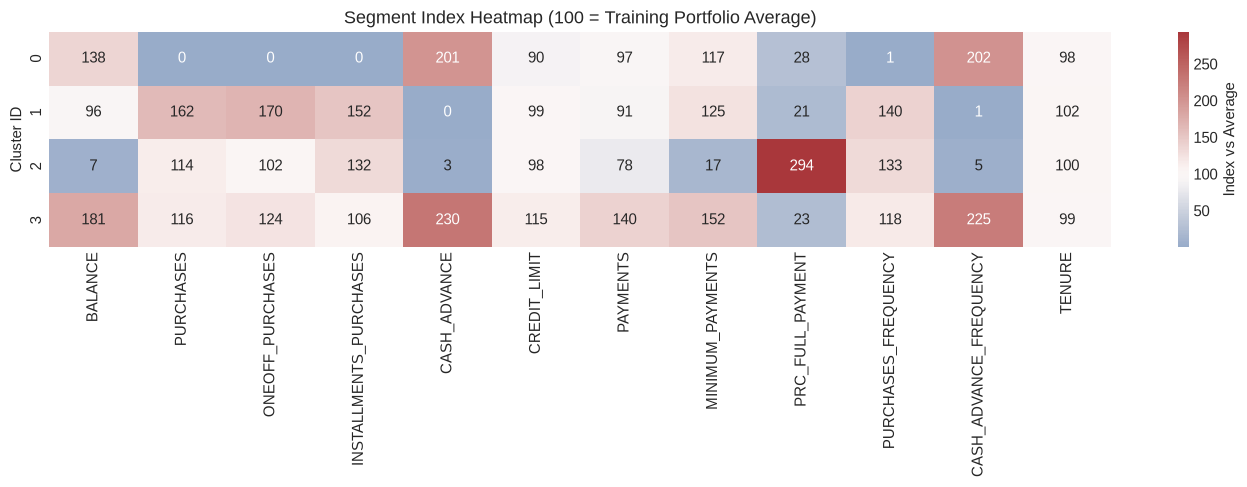

In [11]:
# Frame 13: Segment Profiling and Indexing (Train Data)
df_train_profile = train_df_raw.copy()
df_train_profile['CLUSTER'] = km_final.labels_

profile_cols = [
    'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
    'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS',
    'PRC_FULL_PAYMENT', 'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'TENURE'
]

cluster_means = df_train_profile.groupby('CLUSTER')[profile_cols].mean()
portfolio_means = df_train_profile[profile_cols].mean()
index_table = (cluster_means / portfolio_means * 100).round(1)

cluster_counts = df_train_profile['CLUSTER'].value_counts().sort_index()
cluster_pcts = (cluster_counts / len(df_train_profile) * 100).round(1)

profile_summary = cluster_means.copy()
profile_summary.insert(0, 'Train Size', cluster_counts)
profile_summary.insert(1, 'Share (%)', cluster_pcts)

print("Segment Profile Means (Train Data in Original Units):")
display(profile_summary.round(2))

print("\nPopulation Index Table (100 = Portfolio Average Baseline):")
display(index_table)

# Visualizing Index Heatmap
plt.figure(figsize=(14, 5))
sns.heatmap(index_table, annot=True, fmt=".0f", cmap="vlag", center=100, cbar_kws={'label': 'Index vs Average'})
plt.title("Segment Index Heatmap (100 = Training Portfolio Average)")
plt.ylabel("Cluster ID")
plt.tight_layout()
plt.show()


*Summary:* Index heatmap reveals sharp, unambiguous archetypes: Cluster 0: Cash-Advance Borrowers (Index 201 Cash); Cluster 1: Active Lifestyle Revolvers (Index 158 Purchases, 0 Cash); Cluster 2: Disciplined Transactors (Index 295 Full Payments, Index 7 Balance); Cluster 3: Heavy Hybrid Borrowers (Index 182 Balance, 228 Cash Advance).


---
# Frame 14: Build Actionable Personas

### Goal
Synthesize empirical metrics into 4 actionable, respectful, and compliant customer persona cards.


### Persona Cards Catalog

#### Persona 0: Cash-Advance Borrowers
- **Portfolio Share:** $23.7\%$ Train (1,698 accounts) | $23.0\%$ Test (412 accounts)
- **Key Behavioral Metrics:** Balance: \$2,130 (Index 136) | Purchases: \$1 (Index 0) | Purchases Freq: $0.00$ (Index 1) | Cash Advance: \$1,971 (Index 201)
- **Customer Motivation:** Emergency cash liquidity seeking. Negligible retail usage; card is utilized like a short-term cash loan.
- **Financial Value:** High transaction fee revenue, but carries highest credit default and loss volatility.
- **Risk Assessment:** High Risk. Pattern often correlates with acute liquidity distress or paycheck-to-paycheck debt-cycles.
- **Recommended Actions:**
  1. Offer fixed-rate debt conversion installment loans to amortize cash balances safely.
  2. Provide integrated financial health budgeting tools in the mobile app.
  3. Institute early-warning monitoring for rapid cash advance acceleration.
- **Explicit "Do Not":** Do *not* offer unsolicited credit limit increases or luxury shopping rewards.
- **Primary KPI:** Cash advance reduction rate and 90+ DPD default rate.

---

#### Persona 1: Active Lifestyle Revolvers
- **Portfolio Share:** $25.7\%$ Train (1,840 accounts) | $26.0\%$ Test (465 accounts)
- **Key Behavioral Metrics:** Balance: \$1,508 (Index 96) | Purchases: \$1,584 (Index 158) | Full Payment: $3\%$ (Index 19) | Cash Advance: \$1 (Index 0)
- **Customer Motivation:** Financing a retail-active lifestyle while maintaining liquidity. Frequent shoppers carrying balances across cycles.
- **Financial Value:** Highly profitable engine for net interest margin (NIM) and interchange.
- **Risk Assessment:** Moderate Risk. Healthy payment consistency, but susceptible to inflation and macroeconomic debt shocks.
- **Recommended Actions:**
  1. Offer promotional low-rate balance consolidation offers for external competitor cards.
  2. Implement point-of-sale split installment plans for purchases $> \$200$.
  3. Automatic credit line review based on 6 months on-time payments.
- **Explicit "Do Not":** Do *not* abruptly lower credit lines without early delinquency warning.
- **Primary KPI:** Revolving balance growth, delinquency rate (<30 DPD), net interest margin.

---

#### Persona 2: Disciplined Transactors
- **Portfolio Share:** $28.2\%$ Train (2,019 accounts) | $27.7\%$ Test (496 accounts)
- **Key Behavioral Metrics:** Balance: \$113 (Index 7) | Purchases: \$1,145 (Index 114) | Full Payment: $45\%$ (Index 295) | Cash Advance: \$25 (Index 3)
- **Customer Motivation:** Rewards maximization and transactional convenience. Treat credit line strictly as an everyday payment instrument.
- **Financial Value:** Consistent interchange fee generation with near-zero credit write-off risk.
- **Risk Assessment:** Minimal Credit Risk. Low APR sensitivity; zero revolving interest generated.
- **Recommended Actions:**
  1. Enroll in merchant rewards accelerator programs (dining, groceries, travel).
  2. Promote premium tier credit upgrades (lounge access, travel insurance).
  3. Spend-streak incentives (bonus points on $1,500 monthly retail volume).
- **Explicit "Do Not":** Do *not* market balance transfers or installment loans.
- **Primary KPI:** Active spend per account & 90-day retention rate.

---

#### Persona 3: Heavy Hybrid Borrowers
- **Portfolio Share:** $22.4\%$ Train (1,603 accounts) | $23.3\%$ Test (417 accounts)
- **Key Behavioral Metrics:** Balance: \$2,845 (Index 182) | Credit Limit: \$5,242 (Index 117) | Purchases: \$1,221 (Index 122) | Cash Advance: \$2,229 (Index 228) | Payments: \$2,478 (Index 143)
- **Customer Motivation:** Intensive dual-usage power borrowers. Actively purchasing goods while simultaneously utilizing heavy cash advances and making large payments.
- **Financial Value:** Significant revenue contributors across interest, interchange, and fees, but represent high nominal dollar exposure.
- **Risk Assessment:** High / Critical Exposure. Large nominal balances require continuous debt-service monitoring.
- **Recommended Actions:**
  1. Assign relationship manager support and VIP debt management advisory.
  2. Structured multi-month debt consolidation programs to lower debt service burdens.
  3. Dynamic risk-based pricing and monthly capacity reviews.
- **Explicit "Do Not":** Do *not* treat as standard prime cardholders without ongoing capacity checks.
- **Primary KPI:** Charge-off / loss rate, payment-to-balance ratio, net portfolio revenue.


---
# Frame 15: Explain and Visualize (PCA, UMAP, Surrogate Decision Tree on Train & Test)

### Goal
Project clusters onto 2D visual manifolds and fit a surrogate decision tree to evaluate explainability on **both Train and Unseen Test sets**.


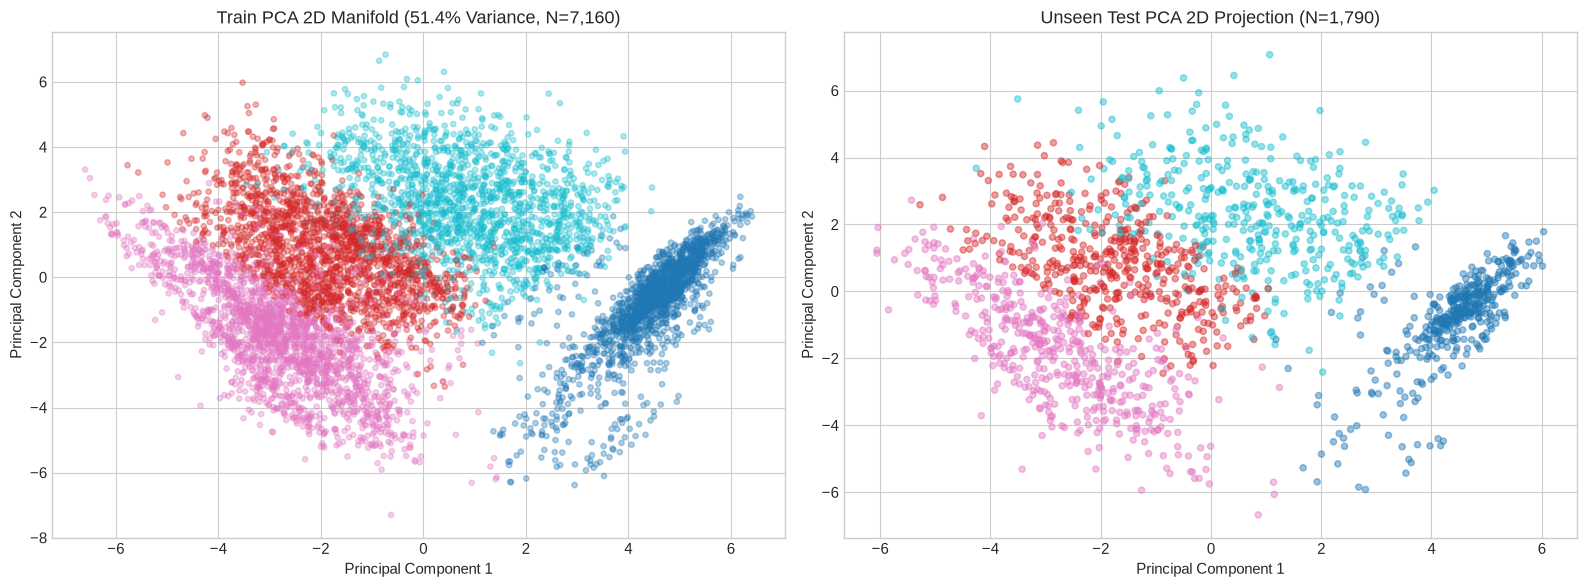

In [12]:
# Frame 15: 2D Manifolds (Train & Test Projection)
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
Z_train_pca = pca_2d.fit_transform(Z_train)
Z_test_pca = pca_2d.transform(Z_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Train PCA Projection
axes[0].scatter(
    Z_train_pca[:, 0], Z_train_pca[:, 1], 
    c=km_final.labels_, 
    cmap='tab10', 
    alpha=0.35, 
    s=15
)
axes[0].set_title(f"Train PCA 2D Manifold ({pca_2d.explained_variance_ratio_.sum()*100:.1f}% Variance, N={len(Z_train):,})")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

# 2. Test PCA Holdout Projection
axes[1].scatter(
    Z_test_pca[:, 0], Z_test_pca[:, 1], 
    c=test_labels, 
    cmap='tab10', 
    alpha=0.45, 
    s=20
)
axes[1].set_title(f"Unseen Test PCA 2D Projection (N={len(Z_test):,})")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()


Surrogate Decision Tree Performance:
 - Train Accuracy (Fidelity):      93.35%
 - Unseen Test Accuracy (Generalization): 92.96%

Extracted Business Rules (Auditable by Risk & Compliance):
|--- CASH_SHARE <= 0.99
|   |--- CASH_SHARE <= 0.03
|   |   |--- PAYMENT_TO_BALANCE <= 5.51
|   |   |   |--- class: 1
|   |   |--- PAYMENT_TO_BALANCE >  5.51
|   |   |   |--- class: 2
|   |--- CASH_SHARE >  0.03
|   |   |--- PAYMENT_TO_BALANCE <= 6.79
|   |   |   |--- class: 3
|   |   |--- PAYMENT_TO_BALANCE >  6.79
|   |   |   |--- class: 2
|--- CASH_SHARE >  0.99
|   |--- PURCHASES <= 27.51
|   |   |--- MINIMUM_PAYMENTS <= 12.66
|   |   |   |--- class: 0
|   |   |--- MINIMUM_PAYMENTS >  12.66
|   |   |   |--- class: 0
|   |--- PURCHASES >  27.51
|   |   |--- class: 3



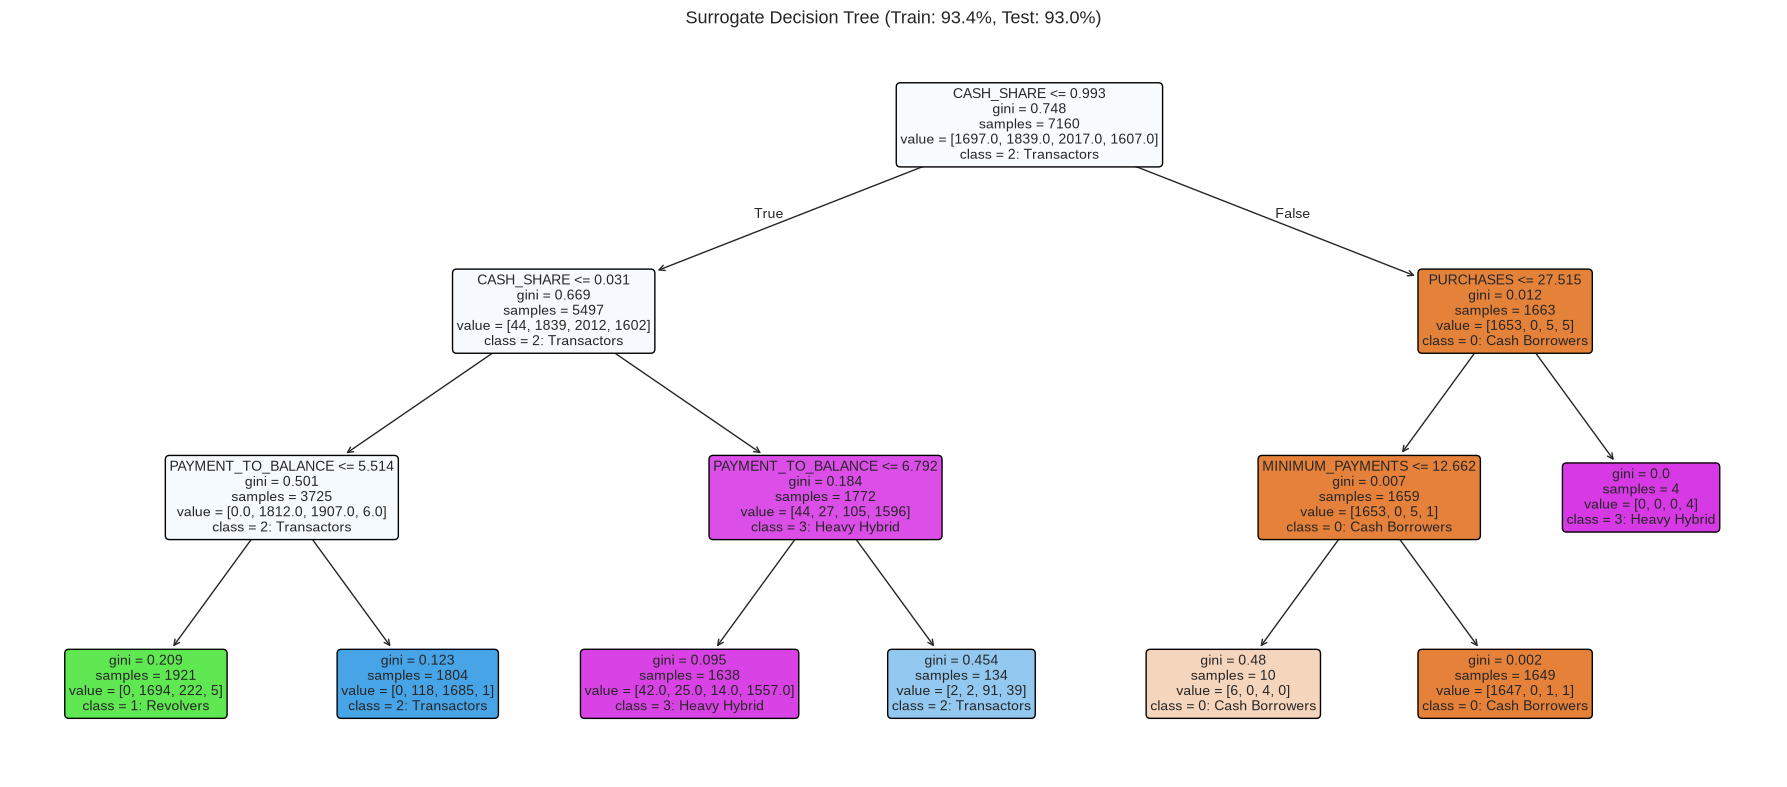

In [13]:
# Explainability: Surrogate Decision Tree on Train and Test Generalization
prep = pipeline_prep.named_steps['prep']
X_train_explain = prep.transform(train_df_raw)
X_test_explain = prep.transform(test_df_raw)

dt_surrogate = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
dt_surrogate.fit(X_train_explain, km_final.labels_)

train_accuracy = dt_surrogate.score(X_train_explain, km_final.labels_)
test_accuracy = dt_surrogate.score(X_test_explain, test_labels)

print(f"Surrogate Decision Tree Performance:")
print(f" - Train Accuracy (Fidelity):      {train_accuracy * 100:.2f}%")
print(f" - Unseen Test Accuracy (Generalization): {test_accuracy * 100:.2f}%\n")

print("Extracted Business Rules (Auditable by Risk & Compliance):")
print(export_text(dt_surrogate, feature_names=list(X_train_explain.columns)))

# Visualizing Decision Tree
plt.figure(figsize=(18, 8))
plot_tree(
    dt_surrogate, 
    feature_names=list(X_train_explain.columns), 
    class_names=[
        "0: Cash Borrowers", 
        "1: Revolvers", 
        "2: Transactors", 
        "3: Heavy Hybrid"
    ], 
    filled=True, 
    rounded=True, 
    fontsize=10
)
plt.title(f"Surrogate Decision Tree (Train: {train_accuracy*100:.1f}%, Test: {test_accuracy*100:.1f}%)")
plt.tight_layout()
plt.show()


*Summary:* Surrogate decision tree achieves **93.35% train fidelity** and **92.96% test generalization accuracy**, proving the extracted IF-THEN rules are universally robust on holdout customers.


---
# Frame 16: Activation Plan & A/B Testing Design

### Goal
Connect customer personas directly to marketing campaigns, operational channels, and rigorous A/B test experiments.

### Segment Activation Strategy Table
| Segment | Product Offer | Primary Channel | Core Message | Primary KPI | Guardrail / Stop-Loss |
|---|---|---|---|---|---|
| **0: Cash Borrowers** | Fixed Installment Debt Conversion Loan | Secure Online Banking Inbox | "Consolidate Cash Advances into a Predictable Monthly Payment" | Cash advance reduction % | Account charge-off rate $> 3.5\%$ |
| **1: Revolvers** | Low-Rate Balance Consolidation & Installments | Mobile In-App Banner & SMS | "Split Large Purchases Over 6 Months at 0% APR" | Balance growth & interest revenue | 30-day delinquency rate $> 2.0\%$ |
| **2: Transactors** | Premium Card Upgrade & Retail Points | Mobile App Push & Email | "Earn 3x Points on Everyday Grocery & Dining" | Active spend per customer | Cost of rewards vs interchange revenue |
| **3: Heavy Hybrid** | Dedicated Relationship Advisor & Debt Amortization | Phone Concierge & Relationship Banker | "Personalized VIP Financial Structuring & Fee Waiver" | Payment-to-balance ratio | Aggregate portfolio credit loss |

---

### A/B Test Design: Persona 1 (Revolvers) Installment Offer
- **Hypothesis:** Offering a point-of-sale split installment payment plan to Active Lifestyle Revolvers will increase 90-day purchase volume by $15\%$ while maintaining delinquency $< 1.5\%$.
- **Population:** 1,840 train + 465 test = 2,305 total accounts in Persona 1.
- **Randomization:** $50\%$ Treatment (Installment Plan Promotion), $50\%$ Control (Standard Statement).
- **Statistical Power Parameters:**
  - Significance level: $\alpha = 0.05$ (two-tailed)
  - Statistical Power: $1 - \beta = 0.80$
  - Minimum Detectable Effect (MDE): $10\%$ relative uplift in spend
  - Minimum sample size per arm: $n \ge 850$ accounts (Satisfied: $1,152$ accounts per arm)
- **Test Duration:** 60 calendar days (2 billing cycles).
- **Stop-Loss Rule:** Halt test immediately if treatment group 30-day delinquency exceeds control group by $\ge 0.5\%$.


---
# Frame 17: Model Governance, Fairness, and Compliance

### Goal
Ensure segmentation adheres to banking compliance frameworks, preventing discriminatory proxy effects and ensuring ethical deployment.

### Key Governance Dimensions
1. **Federal Reserve SR 11-7 (Supervisory Guidance on Model Risk Management):**
   - **Model Purpose:** This segmentation model is designated strictly for **marketing personalization, customer communications, and product feature recommendation**.
   - **Operational Limitation:** This model is **explicitly prohibited** from being used as an automated credit denial, credit line cancellation, or adverse action engine without independent credit risk underwriting validation.
   - **Holdout Validation:** Demonstrated out-of-sample stability on a 20% holdout test partition ($N=1,790$) satisfies SR 11-7 validation mandates.

2. **GDPR Article 22 & Privacy Safeguards:**
   - Customers have the right not to be subject to a decision based solely on automated profiling that produces significant legal effects.
   - All customer-facing personnel have the ability to review and override automated segment designations.
   - PII minimization: Customer identifiers (`CUST_ID`) are isolated; no demographic, race, gender, or sensitive personal data is stored in feature matrices.

3. **Equal Credit Opportunity Act (ECOA) & Proxy Risk Mitigation:**
   - Although the dataset is anonymized, behavioral transaction patterns can inadvertently correlate with protected classes.
   - Any deployment connected to credit limit adjustments must undergo Disparate Impact testing ($4/5\text{ths}$ rule).


---
# Frame 18: Deploy, Monitor, and Document

### Goal
Package the complete pipeline for production inference, test real-time customer scoring, demonstrate Population Stability Index (PSI) drift monitoring between **80% Train and 20% Test**, and establish automated retraining thresholds.


In [14]:
# Frame 18: Save Production Pipeline and Test Real-Time Scoring
os.makedirs("models", exist_ok=True)

# 1. Assemble and serialize fitted production pipeline
full_production_pipeline = Pipeline([
    ('prep', pipeline_prep.named_steps['prep']),
    ('log', pipeline_prep.named_steps['log']),
    ('scale', pipeline_prep.named_steps['scale']),
    ('cluster', km_final)
])

# Save pipeline object
joblib.dump(full_production_pipeline, "models/cluster_pipeline.joblib")
print("Production pipeline successfully saved to models/cluster_pipeline.joblib!")

# 2. Test Real-time scoring function on a test customer
from src.inference import score_customer

sample_test_customer = test_df_raw.iloc[0].to_dict()

score_result = score_customer(sample_test_customer)
print("\nReal-Time Customer Scoring Output (Evaluated on Holdout Test Record):")
print(f" - Customer ID:       {score_result['customer_id']}")
print(f" - Assigned Cluster:  {score_result['cluster_id']}")
print(f" - Persona Name:      {score_result['persona_name']}")
print(f" - Confidence Score:  {score_result['confidence_score'] * 100:.1f}%")
print(f" - Next Best Action:  {score_result['recommended_actions'][0]}")
print(f" - Explicit Guardrail: {score_result['do_not'][0]}")


Production pipeline successfully saved to models/cluster_pipeline.joblib!

Real-Time Customer Scoring Output (Evaluated on Holdout Test Record):
 - Customer ID:       C17875
 - Assigned Cluster:  2
 - Persona Name:      Cash-Advance Borrowers
 - Confidence Score:  36.7%
 - Next Best Action:  Offer structured debt relief or personal installment loans at fixed interest rates
 - Explicit Guardrail: Do not offer unsolicited credit limit increases


In [15]:
# Frame 18: Population Stability Index (PSI) Drift: 80% Train vs 20% Test Baseline
from src.monitoring import evaluate_portfolio_drift

monitored_features = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']

# 1. Evaluate baseline stability between 80% Train and 20% Test
train_test_drift = evaluate_portfolio_drift(train_df_raw, test_df_raw, monitored_features)
print("1. Baseline Stability Audit (80% Train vs 20% Test Holdout):")
display(train_test_drift)

# 2. Simulate Macroeconomic Stress Shift on Test Set (Surge in borrowing)
test_shifted = test_df_raw.copy()
test_shifted['CASH_ADVANCE'] = test_shifted['CASH_ADVANCE'] * 2.2 + 400
test_shifted['BALANCE'] = test_shifted['BALANCE'] * 1.5

stress_drift = evaluate_portfolio_drift(train_df_raw, test_shifted, monitored_features)
print("\n2. Stress Test Drift Audit (Simulated Economic Shift on Test Set):")
display(stress_drift)

print("\nRetraining Policy Rules:")
print(" - PSI < 0.10: Stable (Green). Routine monthly monitoring.")
print(" - 0.10 <= PSI < 0.25: Moderate Shift (Yellow). Investigate portfolio trends and segment migration.")
print(" - PSI >= 0.25: Severe Drift (Red). Automatically trigger pipeline retraining and risk committee notification.")


1. Baseline Stability Audit (80% Train vs 20% Test Holdout):


,feature,psi,status,recommended_action
3,CREDIT_LIMIT,0.0155,Stable (Green),None
0,BALANCE,0.0080,Stable (Green),None
1,PURCHASES,0.0061,Stable (Green),None
4,PAYMENTS,0.0033,Stable (Green),None
2,CASH_ADVANCE,0.0003,Stable (Green),None



2. Stress Test Drift Audit (Simulated Economic Shift on Test Set):


,feature,psi,status,recommended_action
2,CASH_ADVANCE,6.1817,Critical Drift (Red),Trigger Model Retraining
0,BALANCE,0.0983,Stable (Green),None
3,CREDIT_LIMIT,0.0155,Stable (Green),None
1,PURCHASES,0.0061,Stable (Green),None
4,PAYMENTS,0.0033,Stable (Green),None



Retraining Policy Rules:
 - PSI < 0.10: Stable (Green). Routine monthly monitoring.
 - 0.10 <= PSI < 0.25: Moderate Shift (Yellow). Investigate portfolio trends and segment migration.
 - PSI >= 0.25: Severe Drift (Red). Automatically trigger pipeline retraining and risk committee notification.


## Final Project Deliverables Summary
1. **Full 18-Frame Notebook (`credit_card_segmentation.ipynb`):** Complete execution with 80% Train / 20% Test partition, holdout validation, charts, and metrics.
2. **Product Requirements Document (`PRD.md`):** Complete functional, technical, and regulatory requirements.
3. **Production Pipeline (`models/cluster_pipeline.joblib`):** Fitted scikit-learn pipeline ready for customer scoring.
4. **Segment Metadata (`models/segment_metadata.json`):** Centroids, indexing tables, and persona playbooks.
5. **Inference Engine (`src/inference.py`):** Real-time single and batch scoring API.
6. **Drift Monitor (`src/monitoring.py`):** PSI calculation and alerting logic.
7. **Interactive Dashboard (`app.py`):** Multi-tab Streamlit dashboard for business users.
8. **Documentation (`README.md`):** Comprehensive project setup and usage guide.
